Importing the Libraries

In [196]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

Load the datasets

In [197]:
sales_data = pd.read_csv(r'C:\Users\USER\OneDrive\Desktop\Python Lesson\data-analyst\data\pharmacy_sales_raw.csv')

In [198]:
sales_data.head()

,order_id,order_date,delivery_date,customer_id,customer_name,customer_phone,customer_email,customer_gender,customer_age,city,...,expiry_date,unit_price_kes,quantity,discount_pct,promo_code,total_amount_kes,delivery_fee_kes,payment_method,customer_rating,customer_review
0,ORD-101260,2026-03-01 13:32,NaN,CUS00473,Njeri Onyango,0799 297 864,njerionyango@gmail.com,Female,39.0,Nairobi,...,10/2026,134.0,1.0,0.0,NaN,134.0,0.0,Card,4.0,NaN
1,ORD-102354,2026-04-21 15:37,NaN,CUS00404,Mercy Kamau,0746-061-372,mercy.kamau@icloud.com,Female,45.0,Eldoret,...,01/2028,373.0,1.0,0.0,NaN,373.0,0.0,M-Pesa,3.0,NaN
2,ORD-105391,2026-09-01 12:30,2026-09-01,CUS01110,Ochieng Mutiso,730127413,ochieng_mutiso@gmail.com,Male,49.0,NAIROBI,...,03/2029,1336.0,3.0,0.0,NaN,4008.0,0.0,M-Pesa,4.0,NaN
3,ORD-100305,2026-01-15 12:47,NaN,CUS01757,Barasa Wanjala,0763293198,barasa_wanjala79@outlook.com,Male,32.0,Mombasa,...,07/2027,1045.0,4.0,5.0,MYDEAL5,3971.0,0.0,M-Pesa,4.0,NaN
4,ORD-103519,2026-06-13 18:13,2026-06-13,CUS01348,Omondi Otieno,+254717136055,omondi_otieno@outlook.com,Male,30.0,Nairobi,...,05/2028,985.0,1.0,20.0,WELL20,788.0,150.0,M-Pesa,3.0,"Fine, nothing special"


Pre-Cleaning EDA

In [199]:
def basic_checks(data):
    print('-'* 40, 'Shape', "-"*40)
    print(data.shape)
    print('-'*40, "columns", '-'*40)
    print(data.columns)
    print('-'*40, 'Duplicate Values', '-'*40)
    print(data.duplicated().sum())
    print('-'*40, "Basic Info",'-'*40)
    print(data.info())
    print('-'*40,'Misiing Values','-'*40)
    print(data.isna().sum())
    print('-'*40,'Summary stats','-'*40)
    display(data.describe().T)
    display(data.describe(include= 'object').T)



In [200]:
basic_checks(sales_data)

---------------------------------------- Shape ----------------------------------------
(6150, 26)
---------------------------------------- columns ----------------------------------------
Index(['order_id', 'order_date', 'delivery_date', 'customer_id',
       'customer_name', 'customer_phone', 'customer_email', 'customer_gender',
       'customer_age', 'city', 'branch', 'channel', 'product_id',
       'product_name', 'category', 'requires_prescription', 'expiry_date',
       'unit_price_kes', 'quantity', 'discount_pct', 'promo_code',
       'total_amount_kes', 'delivery_fee_kes', 'payment_method',
       'customer_rating', 'customer_review'],
      dtype='str')
---------------------------------------- Duplicate Values ----------------------------------------
120
---------------------------------------- Basic Info ----------------------------------------
<class 'pandas.DataFrame'>
RangeIndex: 6150 entries, 0 to 6149
Data columns (total 26 columns):
 #   Column                 Non-Null 

,count,mean,std,min,25%,50%,75%,max
customer_age,5784.0,34.913900,24.547685,0.00,27.000,34.0,42.0000,999.0
quantity,6056.0,3.516843,21.401592,-5.00,1.000,2.0,3.0000,500.0
discount_pct,6028.0,9.603351,10.747402,-10.00,0.000,10.0,18.0000,150.0
total_amount_kes,6150.0,2359.303434,2881.583637,30.75,491.675,1313.0,3086.1225,22500.0
delivery_fee_kes,6150.0,77.333333,112.349548,0.00,0.000,0.0,200.0000,300.0
customer_rating,4614.0,3.857824,1.156957,0.00,3.000,4.0,5.0000,10.0


C:\Users\USER\AppData\Local\Temp\ipykernel_14772\1918738384.py:14: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  display(data.describe(include= 'object').T)


,count,unique,top,freq
order_id,6150,6000,ORD-103590,2
order_date,6150,5887,2026-09-04 18:38,3
delivery_date,2836,276,2026-06-09,21
customer_id,6150,1728,CUS01512,11
customer_name,6028,2348,Sharon Wairimu,20
customer_phone,6025,4420,0757598166,6
customer_email,5963,2176,nyambura.wairimu@safaricom.co.ke,11
customer_gender,5963,2,Female,3728
city,6150,12,Nairobi,3267
branch,6088,11,Nakuru West,618


In [201]:
sales_data.isna().sum()

order_id                    0
order_date                  0
delivery_date            3314
customer_id                 0
customer_name             122
customer_phone            125
customer_email            187
customer_gender           187
customer_age              366
city                        0
branch                     62
channel                     0
product_id                  0
product_name                0
category                    0
requires_prescription       0
expiry_date                 0
unit_price_kes            127
quantity                   94
discount_pct              122
promo_code               2435
total_amount_kes            0
delivery_fee_kes            0
payment_method            154
customer_rating          1536
customer_review          3880
dtype: int64

In [202]:
# method 1:
cat_cols = ['customer_gender', 'city', 'branch', 'channel', 'product_name', 'category', 'requires_prescription', 'promo_code', 'payment_method', 'customer_rating']

# method 2:
# cat_columns = sales_data.select_dtypes(include=['str', 'object']).columns.tolist()

# cat_columns

for col in cat_cols:
    print('-'*30, col, '-'*30)
    print(sales_data[col].nunique())
    print(sales_data[col].unique())

------------------------------ customer_gender ------------------------------
2
<StringArray>
['Female', 'Male', nan]
Length: 3, dtype: str
------------------------------ city ------------------------------
12
<StringArray>
[ 'Nairobi',  'Eldoret',  'NAIROBI',  'Mombasa',   'Kisumu',      'NRB',
   'Nakuru',   'kisumu',  'nairobi', 'Nairobi ',      'MSA',  'mombasa']
Length: 12, dtype: str
------------------------------ branch ------------------------------
11
<StringArray>
[          'Karen',    'Eldoret Rupa',        'Kilimani',           'Nyali',
 'Thika Road Mall',     'Kisumu Mega',     'Mombasa CBD',     'Nairobi CBD',
          'Online',       'Westlands',     'Nakuru West',               nan]
Length: 12, dtype: str
------------------------------ channel ------------------------------
3
<StringArray>
['In-store', 'App', 'Online']
Length: 3, dtype: str
------------------------------ product_name ------------------------------
338
<StringArray>
[           'Kotex Ultra Sanitary Pa

__Outliers:__
- Values that fall way above/below the majority

In [203]:
num_cols = sales_data.select_dtypes(include=['float', 'int']).columns.tolist()
num_cols

['customer_age',
 'quantity',
 'discount_pct',
 'total_amount_kes',
 'delivery_fee_kes',
 'customer_rating']

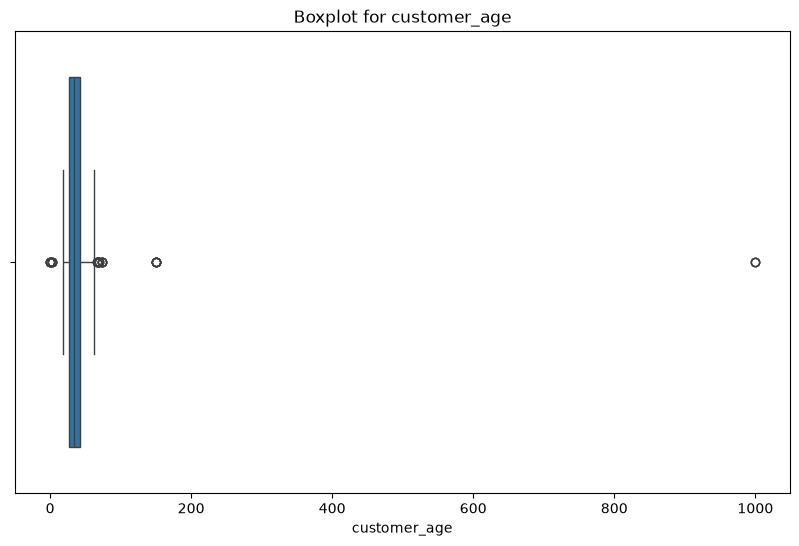

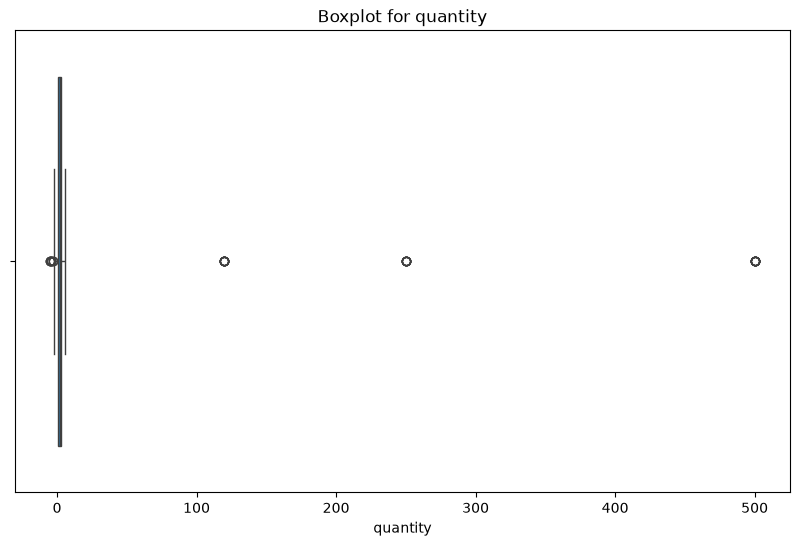

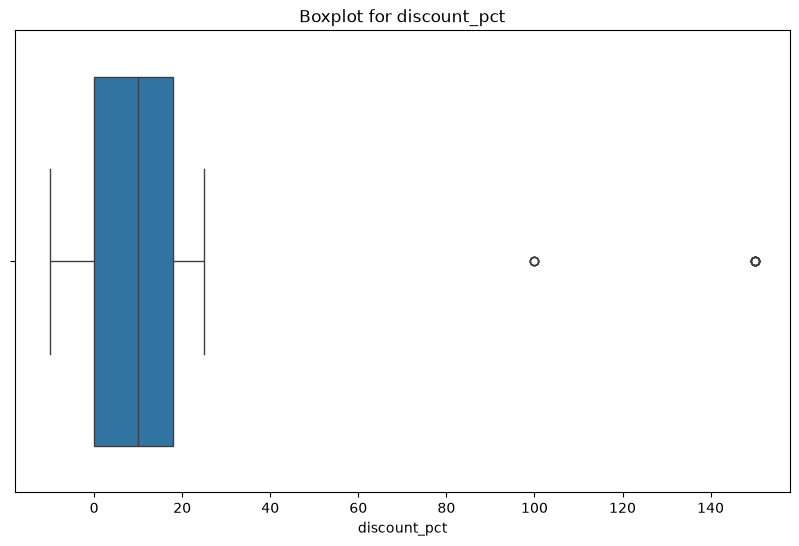

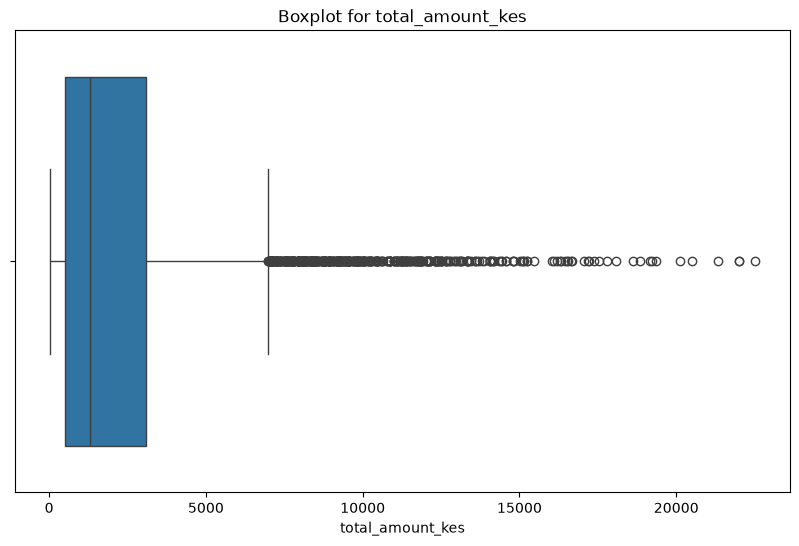

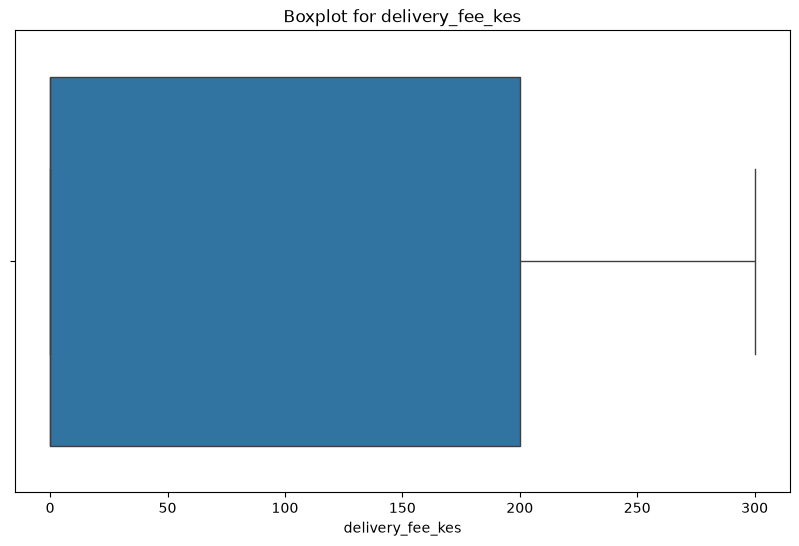

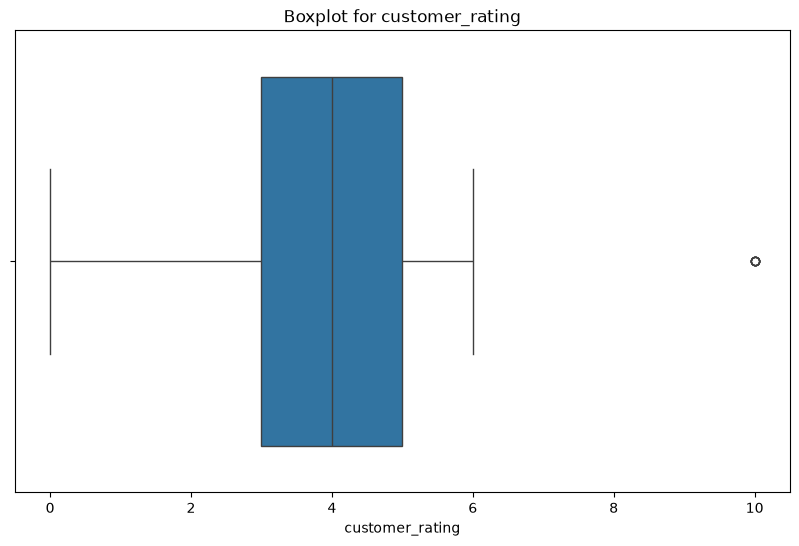

In [204]:
for col in num_cols:
    plt.figure(figsize=(10,6))
    sns.boxplot(data=sales_data, x=col)
    plt.title(f'Boxplot for {col}')
    plt.show()

In [205]:
sales_data.dtypes

order_id                     str
order_date                   str
delivery_date                str
customer_id                  str
customer_name                str
customer_phone               str
customer_email               str
customer_gender              str
customer_age             float64
city                         str
branch                       str
channel                      str
product_id                   str
product_name                 str
category                     str
requires_prescription        str
expiry_date                  str
unit_price_kes               str
quantity                 float64
discount_pct             float64
promo_code                   str
total_amount_kes         float64
delivery_fee_kes         float64
payment_method               str
customer_rating          float64
customer_review              str
dtype: object

## Data Cleaning

Drop Duplicate

In [206]:
df = sales_data.drop_duplicates()

In [207]:
df.duplicated().sum()

np.int64(0)

Cleaning categories in categorical column

__city__

In [208]:
df['city'] = df['city'].replace({
    'NAIROBI' : 'Nairobi',
    "NRB" : 'Nairobi',
    'nairobi' : 'Nairobi',
    'Nairobi ' : 'Nairobi',
    'MSA' : 'Mombasa',
    'mombasa' : 'Mombasa',
    'kisumu' : 'Kisumu'
})

In [209]:
df['city'].unique()

<StringArray>
['Nairobi', 'Eldoret', 'Mombasa', 'Kisumu', 'Nakuru']
Length: 5, dtype: str

__category__

In [210]:
df['category'] = df['category'].replace({
    'Personal care' : 'Personal Care',
    'PERSONAL CARE' : 'Personal Care',
    'personal care' : 'Personal Care',
    'cold & flu' : 'Cold & Flu',
    'COLD & FLU ' : 'Cold & Flu',
    'Cold and Flu' : 'Cold & Flu',
    ' Cold & Flu' : 'Cold & Flu',
    'supplements & nutrition' : 'Supplements & Nutrition',
    'Supplements' : 'Supplements & Nutrition',
    'Mum and Baby' : 'Mum & Baby',
    'mum & baby' : 'Mum & Baby',
    'Mum & Baby ' : 'Mum & Baby',
    'PAIN & INFLAMMATION' : 'Pain & Inflammation',
    'pain & inflammation' : 'Pain & Inflammation',
    'Pain and Inflammation' : 'Pain & Inflammation',
    'Beauty & Skin Care' : 'Dermatological Skincare'
})

In [211]:
df['category'].unique()

<StringArray>
[          'Personal Care',              'Cold & Flu',
 'Supplements & Nutrition',              'Mum & Baby',
 'Dermatological Skincare',     'Pain & Inflammation',
         'Family Planning',         'Medical Devices']
Length: 8, dtype: str

__requires_prescription__

In [212]:
df['requires_prescription'].unique().tolist()

['No', 'FALSE', '0', 'N', 'no', 'Y', 'TRUE', 'Yes', 'yes', '1']

In [213]:
df['requires_prescription'] = df['requires_prescription'].replace({
    'N' : 'No',
    'no' : 'No',
    '0' : 'No',
    'FALSE' : 'No',
    'TRUE' : 'Yes',
    'yes' : 'Yes',
    '1' : 'Yes',
    'Y' : 'Yes'
})

__payment_method__

In [214]:
df['payment_method'].unique()

<StringArray>
[     'Card',    'M-Pesa', 'Insurance',         nan,      'Cash',     'mpesa',
      'CARD',      'Visa',     'MPESA',      'card',    'M-PESA',      'cash',
     'Mpesa',      'CASH']
Length: 14, dtype: str

In [215]:
df['payment_method'] = df['payment_method'].replace({
    'CARD' : 'Card',
    'card' : 'Card',
    'Mpesa' : 'M-Pesa',
    'M-PESA' : 'M-Pesa',
    'MPESA' : 'M-Pesa',
    'mpesa' : 'M-Pesa',
    'cash' : 'Cash',
    'CASH' : 'Cash',
    'Visa' : 'Card'
})

In [216]:
df['product_name'].unique()

<StringArray>
[           'Kotex Ultra Sanitary Pads Super 8's',
        'Nivea Rich Nourishing Body Lotion 200ml',
                    'Olbas Oil For Children 12ml',
                 'Seven Seas Cod Liver Oil 100ml',
                    'NipNap Diaper Junior 5 36's',
                 'Nivea Deo Spray Espresso 150ml',
                           'Oligocare Forte 20's',
 'La Roche-Posay Effaclar Foaming Cleanser 200ml',
               'Fay Antibacterial Wet Wipes 72's',
                           'Zefcolin Syrup 100ml',
 ...
                     '  Aptamil Baby Milk 2 800g',
          '  Panadol Advance 500mg Tablets 100's',
            'Endosan Maternity Pads Large 10's  ',
                          '  Coldcap Syrup 100ml',
                 'Centrum Men 50+ Tablets 30's  ',
    '  Uncover Argan Hydrating Moisturizer 100ml',
                       '  Epimol-E Soap Bar 100g',
        'Panadol Cold & Flu Night Tablets 24's  ',
                        'Wellbaby Liquid 150ml  ',
   'Optima A

__Promo_codes__

In [217]:
df['promo_code'] = df['promo_code'].str.strip().str.upper()

In [218]:
df['promo_code'].unique()

<StringArray>
[        nan,   'MYDEAL5',    'WELL20',    'GLOW25',  'MYDEAL18',    'WELL15',
    'SAVE10',    'WELL25',    'GLOW18',     'GLOW5',   'HEALTH5',    'WELL10',
    'GLOW10',  'MYDEAL10',    'GLOW15',  'MYDEAL25',  'HEALTH25',     'SAVE5',
    'SAVE20', 'MYDEAL-25',    'WELL18',  'HEALTH18',  'MYDEAL20',   'GLOW-25',
    'SAVE25',    'SAVE18',   'GLOW 18',     'WELL5',    'SAVE15',  'HEALTH15',
   'GLOW-10',   'GLOW 25',   'SAVE 25',  'HEALTH20',    'GLOW20',   'WELL 18',
    'SAVE 5',    'SAVE-5',  'HEALTH10',   'WELL 25',  'HEALTH-5',   'WELL-15',
 'MYDEAL 15', 'MYDEAL-15',   'SAVE-25', 'HEALTH-15',  'MYDEAL15', 'HEALTH 18',
   'GLOW-18',  'HEALTH 5',   'SAVE-18',  'MYDEAL-5',   'WELL 20',   'GLOW-20',
 'HEALTH 15', 'MYDEAL-20',   'WELL-25',    'GLOW 5', 'MYDEAL-18',   'WELL-18',
 'HEALTH-18', 'HEALTH 20',    'GLOW-5',   'WELL-20', 'HEALTH-10',   'WELL 10',
   'GLOW-15', 'HEALTH 10',   'SAVE 18', 'MYDEAL 18',   'SAVE-15',   'SAVE-10',
 'HEALTH-25', 'MYDEAL 10',   'SAVE 20'

In [219]:
df['promo_code'] = df['promo_code'].str.replace(r'[\s-]', '', regex=True)

product name

In [220]:
df['product_name'].unique()
# df['product_name'].nunique()

<StringArray>
[           'Kotex Ultra Sanitary Pads Super 8's',
        'Nivea Rich Nourishing Body Lotion 200ml',
                    'Olbas Oil For Children 12ml',
                 'Seven Seas Cod Liver Oil 100ml',
                    'NipNap Diaper Junior 5 36's',
                 'Nivea Deo Spray Espresso 150ml',
                           'Oligocare Forte 20's',
 'La Roche-Posay Effaclar Foaming Cleanser 200ml',
               'Fay Antibacterial Wet Wipes 72's',
                           'Zefcolin Syrup 100ml',
 ...
                     '  Aptamil Baby Milk 2 800g',
          '  Panadol Advance 500mg Tablets 100's',
            'Endosan Maternity Pads Large 10's  ',
                          '  Coldcap Syrup 100ml',
                 'Centrum Men 50+ Tablets 30's  ',
    '  Uncover Argan Hydrating Moisturizer 100ml',
                       '  Epimol-E Soap Bar 100g',
        'Panadol Cold & Flu Night Tablets 24's  ',
                        'Wellbaby Liquid 150ml  ',
   'Optima A

In [221]:
sales_data['product_name'].unique()

<StringArray>
[           'Kotex Ultra Sanitary Pads Super 8's',
        'Nivea Rich Nourishing Body Lotion 200ml',
                    'Olbas Oil For Children 12ml',
                 'Seven Seas Cod Liver Oil 100ml',
                    'NipNap Diaper Junior 5 36's',
                 'Nivea Deo Spray Espresso 150ml',
                           'Oligocare Forte 20's',
 'La Roche-Posay Effaclar Foaming Cleanser 200ml',
               'Fay Antibacterial Wet Wipes 72's',
                           'Zefcolin Syrup 100ml',
 ...
                     '  Aptamil Baby Milk 2 800g',
          '  Panadol Advance 500mg Tablets 100's',
            'Endosan Maternity Pads Large 10's  ',
                          '  Coldcap Syrup 100ml',
                 'Centrum Men 50+ Tablets 30's  ',
    '  Uncover Argan Hydrating Moisturizer 100ml',
                       '  Epimol-E Soap Bar 100g',
        'Panadol Cold & Flu Night Tablets 24's  ',
                        'Wellbaby Liquid 150ml  ',
   'Optima A

In [222]:
df['product_name'] = df['product_name'].str.strip().str.capitalize()

product id

In [223]:
df['product_id'].unique()

<StringArray>
['PRD0112', 'PRD0115', 'PRD0025', 'PRD0057', 'PRD0085', 'PRD0125', 'PRD0061',
 'PRD0165', 'PRD0113', 'PRD0034',
 ...
 'PRD0171', 'PRD0101', 'PRD0106', 'PRD0114', 'PRD0172', 'PRD0169', 'PRD0010',
 'PRD0161', 'PRD0006', 'PRD0098']
Length: 189, dtype: str

In [224]:
df.sample(10, random_state=30)

,order_id,order_date,delivery_date,customer_id,customer_name,customer_phone,customer_email,customer_gender,customer_age,city,...,expiry_date,unit_price_kes,quantity,discount_pct,promo_code,total_amount_kes,delivery_fee_kes,payment_method,customer_rating,customer_review
5685,ORD-100634,2026-01-30 13:09,NaN,CUS00544,Atieno Kamau,254714744205,ATIENO_KAMAU@GMAIL.COM,Female,42.0,Mombasa,...,08/2027,3205.0,2.0,20.0,SAVE20,5128.00,0.0,Card,NaN,NaN
712,ORD-103624,2026-06-18 17:32,2026-06-19,CUS00612,Naliaka Ali,+254746523864,NaN,Female,NaN,Nairobi,...,11/2027,704.0,5.0,0.0,NaN,3520.00,0.0,Cash,4.0,
1514,ORD-103780,2026-06-25 13:26,NaN,CUS01137,Sharon Kamau,0190 065 315,sharon.kamau@safaricom.co.ke,Female,34.0,Nairobi,...,11/2027,983.0,2.0,25.0,SAVE25,1474.50,0.0,Insurance,5.0,NaN
217,ORD-104780,2026-08-06 16:59,2026-08-10,CUS00767,NaN,+254749588623,wanjiku_kiptoo@safaricom.co.ke,Female,27.0,Nakuru,...,03/2028,1800.0,1.0,0.0,NaN,1800.00,200.0,NaN,5.0,NaN
3449,ORD-103481,2026-06-12 12:42,NaN,CUS00298,kamau kilonzo,0787 719 349,kamaukilonzo@students.uonbi.ac.ke,Male,18.0,Nairobi,...,12/2028,1031.0,5.0,5.0,HEALTH5,4897.25,0.0,M-Pesa,NaN,NaN
1492,ORD-101017,2026-02-18 13:09,NaN,CUS00839,Wanjiku Langat,0775 024 589,wanjiku.langat43@gmail.com,Female,21.0,Nairobi,...,03/2026,535.0,5.0,NaN,NaN,2675.00,0.0,Cash,4.0,Easy to pay with M-Pesa
3221,ORD-100730,2026-02-03 13:18,NaN,CUS00764,Kipchoge Chege,0795838087,kipchoge.chege71@icloud.com,Male,22.0,Nakuru,...,12/2027,1083.0,3.0,5.0,WELL5,3086.55,0.0,NaN,3.0,Product good but price is a bit high
5547,ORD-100552,2026-01-26 12:24,NaN,CUS01150,Faith Wanjala,+254759814725,faithwanjala@gmail.com,Female,29.0,Mombasa,...,05/2028,2133.0,1.0,0.0,NaN,2133.00,0.0,Card,NaN,NaN
3565,ORD-105590,2026-09-11 12:37,2026-09-12,CUS01669,Joy Hassan,0758512910,joyhassan@gmail.com,Female,34.0,Nairobi,...,10/2027,1735.0,1.0,15.0,MYDEAL15,1474.75,150.0,M-Pesa,3.0,Product good but price is a bit high
4904,ORD-103243,2026-06-03 16:42,2026-06-03,CUS00084,kamau njoroge,0116168781,kamaunjoroge@students.uonbi.ac.ke,Male,48.0,Nairobi,...,10/2028,KES 507,4.0,5.0,GLOW5,1926.60,300.0,M-Pesa,5.0,NaN


customer name

In [225]:
df['customer_name'].unique()

<StringArray>
[       'Njeri Onyango',          'Mercy Kamau',       'Ochieng Mutiso',
       'Barasa Wanjala',        'Omondi Otieno',         'Atieno Maina',
        'Wambui Otieno', '  Muthoni   Kilonzo ',           'Faith Ruto',
        'Mutua Achieng',
 ...
        'kiprono owino',         'NJERI NDUNGU',       'sharon njoroge',
       'WAFULA ACHIENG',      'achieng wairimu',         'jebet wekesa',
     '  Chebet   Ruto ',  '  Victor   Kariuki ',         'esther chege',
           'KIBET RUTO']
Length: 2349, dtype: str

In [226]:
df['customer_name'] = df['customer_name'].str.strip().str.replace(r'\s+', ' ', regex=True).str.title()

checking duplicates

In [227]:
df['order_id'].duplicated().sum()

np.int64(30)

In [228]:
df['order_id_duplicated'] = df['order_id'].duplicated()
df.loc[df['order_id_duplicated'], 'order_id'].head(30)

797     ORD-104979
1484    ORD-102748
1789    ORD-103453
2559    ORD-100547
2809    ORD-103586
3174    ORD-100555
3182    ORD-101526
3256    ORD-100774
3332    ORD-103180
3675    ORD-101222
3855    ORD-101412
4000    ORD-104738
4167    ORD-103389
4302    ORD-104219
4400    ORD-104790
4413    ORD-105076
4519    ORD-100986
4665    ORD-102186
4776    ORD-104111
4781    ORD-103091
4985    ORD-102959
5037    ORD-101590
5263    ORD-105212
5334    ORD-102989
5518    ORD-104871
5525    ORD-101721
5754    ORD-105701
5853    ORD-105208
5938    ORD-104973
6077    ORD-104487
Name: order_id, dtype: str

In [229]:
df[df['order_id'].duplicated(keep=False)].sort_values(by='order_id')
# create atemp col, based on order_id

,order_id,order_date,delivery_date,customer_id,customer_name,customer_phone,customer_email,customer_gender,customer_age,city,...,unit_price_kes,quantity,discount_pct,promo_code,total_amount_kes,delivery_fee_kes,payment_method,customer_rating,customer_review,order_id_duplicated
2559,ORD-100547,26/01/2026 10:09,NaN,CUS00939,Omondi Njoroge,+254764048604,omondi_njoroge2@gmail.com,Male,39.0,Mombasa,...,156.0,4.0,15.0,MYDEAL15,530.40,0.0,Insurance,NaN,NaN,True
2328,ORD-100547,26/01/2026 10:09,NaN,CUS00939,Omondi Njoroge,+254764048604,omondi_njoroge2@gmail.com,Male,39.0,Mombasa,...,156.0,5.0,15.0,MYDEAL15,530.40,0.0,Insurance,NaN,NaN,False
3174,ORD-100555,"Jan 26, 2026",2026-01-30,CUS00875,Samuel Chege,0722315917,samuelchege@gmail.com,Male,26.0,Nakuru,...,666.0,5.0,0.0,NaN,3330.00,0.0,Card,2.0,NaN,True
990,ORD-100555,"Jan 26, 2026",2026-01-30,CUS00875,Samuel Chege,0722315917,samuelchege@gmail.com,Male,26.0,Nakuru,...,666.0,6.0,0.0,NaN,3330.00,0.0,Card,2.0,NaN,False
793,ORD-100774,2026-02-05 11:18,NaN,CUS01603,Faith Kimani,710942635,faithkimani69@gmail.com,Female,30.0,Nairobi,...,142.0,5.0,0.0,NaN,568.00,0.0,M-Pesa,4.0,NaN,False
3256,ORD-100774,2026-02-05 11:18,NaN,CUS01603,Faith Kimani,710942635,faithkimani69@gmail.com,Female,30.0,Nairobi,...,142.0,4.0,0.0,NaN,568.00,0.0,M-Pesa,4.0,NaN,True
904,ORD-100986,2026-02-16 19:36,2026-02-17,CUS00682,Atieno Owino,+254772945298,atienoowino84@gmail.com,Female,40.0,Mombasa,...,167.0,4.0,20.0,SAVE20,400.80,300.0,M-Pesa,5.0,Delivered to my office in Westlands within hours,False
4519,ORD-100986,2026-02-16 19:36,2026-02-17,CUS00682,Atieno Owino,+254772945298,atienoowino84@gmail.com,Female,40.0,Mombasa,...,167.0,3.0,20.0,SAVE20,400.80,300.0,M-Pesa,5.0,Delivered to my office in Westlands within hours,True
3675,ORD-101222,2026-02-27 19:28,2026-02-28,CUS01745,Jebet Wekesa,0191589550,jebetwekesa86@gmail.com,Female,29.0,Eldoret,...,384.0,2.0,15.0,GLOW15,326.40,250.0,Cash,4.0,"Poa sana, packaging was neat",True
293,ORD-101222,2026-02-27 19:28,2026-02-28,CUS01745,Jebet Wekesa,0191589550,jebetwekesa86@gmail.com,Female,29.0,Eldoret,...,384.0,1.0,15.0,GLOW15,326.40,250.0,Cash,4.0,"Poa sana, packaging was neat",False


In [230]:
df[df.duplicated(subset=['order_id'], keep=False)]

,order_id,order_date,delivery_date,customer_id,customer_name,customer_phone,customer_email,customer_gender,customer_age,city,...,unit_price_kes,quantity,discount_pct,promo_code,total_amount_kes,delivery_fee_kes,payment_method,customer_rating,customer_review,order_id_duplicated
21,ORD-103091,2026-05-28 13:15,NaN,CUS00051,Kibet Langat,0773-448-609,kibet.langat@gmail.com,NaN,45.0,Kisumu,...,393.0,4.0,5.0,MYDEAL5,1493.40,0.0,M-Pesa,4.0,Good price compared to other shops,False
293,ORD-101222,2026-02-27 19:28,2026-02-28,CUS01745,Jebet Wekesa,0191589550,jebetwekesa86@gmail.com,Female,29.0,Eldoret,...,384.0,1.0,15.0,GLOW15,326.40,250.0,Cash,4.0,"Poa sana, packaging was neat",False
306,ORD-104979,2026-08-15 09:41,2026-08-15,CUS00743,Dennis Mutiso,+254795476521,dennismutiso@students.uonbi.ac.ke,Male,42.0,Nairobi,...,10290.0,1.0,5.0,SAVE5,9775.50,0.0,M-Pesa,5.0,Works well for my family,False
433,ORD-102748,2026-05-10 18:41,2026-05-07,CUS00016,Muthoni Maina,+254789080117,muthonimaina91@gmail.com,Female,46.0,Nairobi,...,43.0,2.0,18.0,WELL18,70.52,150.0,M-Pesa,5.0,NaN,False
779,ORD-101590,2026-03-16 18:09,NaN,CUS00154,Nekesa Kimani,+254131472599,nekesakimani30@outlook.com,Female,23.0,Mombasa,...,2229.0,5.0,0.0,NaN,8916.00,0.0,M-Pesa,4.0,Works well for my family,False
793,ORD-100774,2026-02-05 11:18,NaN,CUS01603,Faith Kimani,710942635,faithkimani69@gmail.com,Female,30.0,Nairobi,...,142.0,5.0,0.0,NaN,568.00,0.0,M-Pesa,4.0,NaN,False
797,ORD-104979,2026-08-15 09:41,2026-08-15,CUS00743,Dennis Mutiso,+254795476521,dennismutiso@students.uonbi.ac.ke,Male,42.0,Nairobi,...,10290.0,2.0,5.0,SAVE5,9775.50,0.0,M-Pesa,5.0,Works well for my family,True
801,ORD-102186,2026-04-13 19:24,2026-04-14,CUS01749,Purity Otieno,NaN,purity_otieno@outlook.com,Female,19.0,Nairobi,...,381.0,2.0,10.0,SAVE10,342.90,200.0,Cash,5.0,NaN,False
811,ORD-103389,2026-06-08 18:50,2026-06-09,CUS00401,Nyambura Wekesa,0154167171,nyambura.wekesa@gmail.com,Female,32.0,Nairobi,...,431.0,4.0,18.0,SAVE18,1413.68,250.0,Card,3.0,NaN,False
904,ORD-100986,2026-02-16 19:36,2026-02-17,CUS00682,Atieno Owino,+254772945298,atienoowino84@gmail.com,Female,40.0,Mombasa,...,167.0,4.0,20.0,SAVE20,400.80,300.0,M-Pesa,5.0,Delivered to my office in Westlands within hours,False


In [231]:
df[df['order_id'].duplicated(keep=False)].sort_values(by='order_id')

,order_id,order_date,delivery_date,customer_id,customer_name,customer_phone,customer_email,customer_gender,customer_age,city,...,unit_price_kes,quantity,discount_pct,promo_code,total_amount_kes,delivery_fee_kes,payment_method,customer_rating,customer_review,order_id_duplicated
2559,ORD-100547,26/01/2026 10:09,NaN,CUS00939,Omondi Njoroge,+254764048604,omondi_njoroge2@gmail.com,Male,39.0,Mombasa,...,156.0,4.0,15.0,MYDEAL15,530.40,0.0,Insurance,NaN,NaN,True
2328,ORD-100547,26/01/2026 10:09,NaN,CUS00939,Omondi Njoroge,+254764048604,omondi_njoroge2@gmail.com,Male,39.0,Mombasa,...,156.0,5.0,15.0,MYDEAL15,530.40,0.0,Insurance,NaN,NaN,False
3174,ORD-100555,"Jan 26, 2026",2026-01-30,CUS00875,Samuel Chege,0722315917,samuelchege@gmail.com,Male,26.0,Nakuru,...,666.0,5.0,0.0,NaN,3330.00,0.0,Card,2.0,NaN,True
990,ORD-100555,"Jan 26, 2026",2026-01-30,CUS00875,Samuel Chege,0722315917,samuelchege@gmail.com,Male,26.0,Nakuru,...,666.0,6.0,0.0,NaN,3330.00,0.0,Card,2.0,NaN,False
793,ORD-100774,2026-02-05 11:18,NaN,CUS01603,Faith Kimani,710942635,faithkimani69@gmail.com,Female,30.0,Nairobi,...,142.0,5.0,0.0,NaN,568.00,0.0,M-Pesa,4.0,NaN,False
3256,ORD-100774,2026-02-05 11:18,NaN,CUS01603,Faith Kimani,710942635,faithkimani69@gmail.com,Female,30.0,Nairobi,...,142.0,4.0,0.0,NaN,568.00,0.0,M-Pesa,4.0,NaN,True
904,ORD-100986,2026-02-16 19:36,2026-02-17,CUS00682,Atieno Owino,+254772945298,atienoowino84@gmail.com,Female,40.0,Mombasa,...,167.0,4.0,20.0,SAVE20,400.80,300.0,M-Pesa,5.0,Delivered to my office in Westlands within hours,False
4519,ORD-100986,2026-02-16 19:36,2026-02-17,CUS00682,Atieno Owino,+254772945298,atienoowino84@gmail.com,Female,40.0,Mombasa,...,167.0,3.0,20.0,SAVE20,400.80,300.0,M-Pesa,5.0,Delivered to my office in Westlands within hours,True
3675,ORD-101222,2026-02-27 19:28,2026-02-28,CUS01745,Jebet Wekesa,0191589550,jebetwekesa86@gmail.com,Female,29.0,Eldoret,...,384.0,2.0,15.0,GLOW15,326.40,250.0,Cash,4.0,"Poa sana, packaging was neat",True
293,ORD-101222,2026-02-27 19:28,2026-02-28,CUS01745,Jebet Wekesa,0191589550,jebetwekesa86@gmail.com,Female,29.0,Eldoret,...,384.0,1.0,15.0,GLOW15,326.40,250.0,Cash,4.0,"Poa sana, packaging was neat",False


In [232]:
df['order_date'].info

<bound method Series.info of 0       2026-03-01 13:32
1       2026-04-21 15:37
2       2026-09-01 12:30
3       2026-01-15 12:47
4       2026-06-13 18:13
              ...       
6145    2026-09-16 13:55
6146    2026-05-01 10:09
6147    2026-01-25 17:45
6148    2026-02-27 17:51
6149    2026-07-16 14:40
Name: order_date, Length: 6030, dtype: str>

In [233]:
df['order_date_cp'] = df['order_date']

In [234]:
df['order_date_cp'] = pd.to_datetime(df['order_date_cp'], format='mixed', dayfirst=True, errors='coerce')

In [235]:
df['order_date_cp']

0      2026-01-03 13:32:00
1      2026-04-21 15:37:00
2      2026-01-09 12:30:00
3      2026-01-15 12:47:00
4      2026-06-13 18:13:00
               ...        
6145   2026-09-16 13:55:00
6146   2026-01-05 10:09:00
6147   2026-01-25 17:45:00
6148   2026-02-27 17:51:00
6149   2026-07-16 14:40:00
Name: order_date_cp, Length: 6030, dtype: datetime64[us]

In [236]:
df['order_date'] = pd.to_datetime(df['order_date'], format='mixed', dayfirst=True, errors='coerce')

In [237]:
df['order_date'].head()

0   2026-01-03 13:32:00
1   2026-04-21 15:37:00
2   2026-01-09 12:30:00
3   2026-01-15 12:47:00
4   2026-06-13 18:13:00
Name: order_date, dtype: datetime64[us]

In [238]:
df['customer_review'].unique()

<StringArray>
[                                               nan,
                            'Fine, nothing special',
                     'POA SANA, PACKAGING WAS NEAT',
                               'Average experience',
             'Product good but price is a bit high',
               'Great customer service on WhatsApp',
               'Good price compared to other shops',
         'Pharmacist was very helpful and friendly',
                  'Genuine product, will buy again',
                     'Product exactly as described',
                      'Fast delivery, asante sana!',
                         'Works well for my family',
                  'GENUINE PRODUCT, WILL BUY AGAIN',
                      'Okay but delivery took long',
 'Delivered to my office in Westlands within hours',
                          'Easy to pay with M-Pesa',
                         'WORKS WELL FOR MY FAMILY',
                     'Poa sana, packaging was neat',
           'Wrong item delivered

In [239]:
df['customer_review'] = (
    df['customer_review']
    .str.strip()
    .str.capitalize()
    .str.replace('-', 'None')
    .replace('', 'None')
    .fillna('None')
)
df['customer_review'].unique()

<StringArray>
[                                            'None',
                            'Fine, nothing special',
                     'Poa sana, packaging was neat',
                               'Average experience',
             'Product good but price is a bit high',
               'Great customer service on whatsapp',
               'Good price compared to other shops',
         'Pharmacist was very helpful and friendly',
                  'Genuine product, will buy again',
                     'Product exactly as described',
                      'Fast delivery, asante sana!',
                         'Works well for my family',
                      'Okay but delivery took long',
 'Delivered to my office in westlands within hours',
                       'Easy to pay with mNonepesa',
           'Wrong item delivered, had to return it',
                    'Delivery was late by two days',
                          'Package arrived damaged',
             'Poor customer serv

## summary of columns weve cleaned

1. city
2. category
3. requires prescription
4. payment method
5. promo code
6. product name 
7. customer name
8. customers review
9. order date

## Why the timestamp is important

1. To ensure you allocate resources are deployed to cater for the spike in customers
2. ensure stock is enough to cater for spike 
3. ensure inventory can cater for the spike.

customer phone

In [240]:
df['customer_phone']

0        0799 297 864
1        0746-061-372
2           730127413
3          0763293198
4       +254717136055
            ...      
6145     0755 607 281
6146    +254752064254
6147       0730738320
6148    +254732718361
6149       0742019036
Name: customer_phone, Length: 6030, dtype: str

## cleaning customer phone
1. spaces before the characters --> strips()
2. dashes betwen the characters --> replace()
3. replace +254 --> 0
4. adding zero to numbers that begin with 7
5. leaving the rest as is

In [241]:
df['customer_phone']

0        0799 297 864
1        0746-061-372
2           730127413
3          0763293198
4       +254717136055
            ...      
6145     0755 607 281
6146    +254752064254
6147       0730738320
6148    +254732718361
6149       0742019036
Name: customer_phone, Length: 6030, dtype: str

In [242]:
def format_phone(phone):
    if pd.isna(phone):
        return phone

    phone = str(phone).strip()
    phone = ''.join(char for char in phone if char.isdigit())

    if phone.startswith("254"):
        phone = "0" + phone[3:]
    elif phone.startswith("00"):
        phone = "07" + phone[2:]

    if phone.startswith("07"):
        return phone
    if phone.startswith("7"):
        return "0" + phone
    if phone.startswith("0"):
        return "07" + phone[1:]

    return "07" + phone


df["customer_phone"] = df["customer_phone"].map(format_phone)

In [243]:
df.head()

,order_id,order_date,delivery_date,customer_id,customer_name,customer_phone,customer_email,customer_gender,customer_age,city,...,quantity,discount_pct,promo_code,total_amount_kes,delivery_fee_kes,payment_method,customer_rating,customer_review,order_id_duplicated,order_date_cp
0,ORD-101260,2026-01-03 13:32:00,NaN,CUS00473,Njeri Onyango,0799297864,njerionyango@gmail.com,Female,39.0,Nairobi,...,1.0,0.0,NaN,134.0,0.0,Card,4.0,None,False,2026-01-03 13:32:00
1,ORD-102354,2026-04-21 15:37:00,NaN,CUS00404,Mercy Kamau,0746061372,mercy.kamau@icloud.com,Female,45.0,Eldoret,...,1.0,0.0,NaN,373.0,0.0,M-Pesa,3.0,None,False,2026-04-21 15:37:00
2,ORD-105391,2026-01-09 12:30:00,2026-09-01,CUS01110,Ochieng Mutiso,0730127413,ochieng_mutiso@gmail.com,Male,49.0,Nairobi,...,3.0,0.0,NaN,4008.0,0.0,M-Pesa,4.0,None,False,2026-01-09 12:30:00
3,ORD-100305,2026-01-15 12:47:00,NaN,CUS01757,Barasa Wanjala,0763293198,barasa_wanjala79@outlook.com,Male,32.0,Mombasa,...,4.0,5.0,MYDEAL5,3971.0,0.0,M-Pesa,4.0,None,False,2026-01-15 12:47:00
4,ORD-103519,2026-06-13 18:13:00,2026-06-13,CUS01348,Omondi Otieno,0717136055,omondi_otieno@outlook.com,Male,30.0,Nairobi,...,1.0,20.0,WELL20,788.0,150.0,M-Pesa,3.0,"Fine, nothing special",False,2026-06-13 18:13:00


In [244]:
df['customer_phone'].unique()

<StringArray>
['0799297864', '0746061372', '0730127413', '0763293198', '0717136055',
 '0725565732', '0764206790', '0739443335', '0796480456', '0768838383',
 ...
       '0759', '0785239135', '0751421173', '0774822842', '0794398858',
 '0793743715', '0729180612', '0744484413',     '078754', '0711951980']
Length: 1756, dtype: str

In [245]:
df.loc[df['customer_phone'].str.len() < 10, 'customer_phone'] = (
    df['customer_phone'].str.pad(width=10, side='right', fillchar='0')
)

In [246]:
df.sample(50)

,order_id,order_date,delivery_date,customer_id,customer_name,customer_phone,customer_email,customer_gender,customer_age,city,...,quantity,discount_pct,promo_code,total_amount_kes,delivery_fee_kes,payment_method,customer_rating,customer_review,order_id_duplicated,order_date_cp
5099,ORD-104604,2026-07-30 17:08:00,NaN,CUS00474,Kibet Achieng,07143826877,kibet.achieng57@safaricom.co.ke,Male,23.0,Eldoret,...,2.0,20.0,SAVE20,827.20,0.0,M-Pesa,5.0,Good price compared to other shops,False,2026-07-30 17:08:00
2148,ORD-104762,2026-06-08 11:11:00,NaN,CUS00108,Brian Wanjala,0751280585,brian.wanjala@gmail.com,Male,38.0,Nakuru,...,1.0,0.0,NaN,204.00,200.0,Card,4.0,None,False,2026-06-08 11:11:00
4721,ORD-102363,2026-04-21 19:03:00,2026-04-23,CUS00188,Njeri Wekesa,0744591138,njeri_wekesa8@yahoo.com,Female,38.0,Nairobi,...,2.0,0.0,NaN,1590.00,300.0,Insurance,4.0,None,False,2026-04-21 19:03:00
5418,ORD-101295,2026-02-03 19:14:00,2026-03-03,CUS01472,Allan Kamau,0794783323,allan_kamau@yahoo.com,Male,28.0,Nairobi,...,5.0,18.0,SAVE18,1189.00,250.0,Cash,3.0,None,False,2026-02-03 19:14:00
5809,ORD-101810,2026-03-27 10:43:00,NaN,CUS01329,Dennis Wairimu,07129250833,dennis_wairimu@icloud.com,Male,54.0,Eldoret,...,5.0,18.0,WELL18,8523.90,0.0,M-Pesa,NaN,None,False,2026-03-27 10:43:00
2122,ORD-102175,2026-04-13 11:49:00,2026-04-13,CUS00202,Chebet Ali,0714048890,chebet.ali@gmail.com,Female,32.0,Nairobi,...,2.0,0.0,NaN,810.00,200.0,Card,2.0,"Product near expiry date, not happy",False,2026-04-13 11:49:00
4950,ORD-100967,2026-02-16 08:02:00,2026-02-18,CUS01684,Achieng Mutua,0740633571,achieng.mutua4@gmail.com,Female,19.0,Nairobi,...,3.0,15.0,HEALTH15,2453.10,300.0,Card,3.0,None,False,2026-02-16 08:02:00
73,ORD-104551,2026-07-28 13:34:00,NaN,CUS01533,Wafula Opiyo,07181897375,wafula_opiyo@gmail.com,Male,39.0,Nakuru,...,1.0,0.0,NaN,1031.00,0.0,Insurance,NaN,None,False,2026-07-28 13:34:00
1041,ORD-105371,2026-08-31 12:30:00,2026-09-02,CUS01659,Nekesa Opiyo,07126223551,nekesa.opiyo@gmail.com,Female,42.0,Eldoret,...,3.0,0.0,NaN,1059.00,150.0,M-Pesa,5.0,None,False,2026-08-31 12:30:00
1492,ORD-101017,2026-02-18 13:09:00,NaN,CUS00839,Wanjiku Langat,0775024589,wanjiku.langat43@gmail.com,Female,21.0,Nairobi,...,5.0,NaN,NaN,2675.00,0.0,Cash,4.0,Easy to pay with mNonepesa,False,2026-02-18 13:09:00


cleaning customer email column

In [247]:
df['customer_email'] = df['customer_email'].str.strip().str.lower()

In [248]:
df.sample(50)

,order_id,order_date,delivery_date,customer_id,customer_name,customer_phone,customer_email,customer_gender,customer_age,city,...,quantity,discount_pct,promo_code,total_amount_kes,delivery_fee_kes,payment_method,customer_rating,customer_review,order_id_duplicated,order_date_cp
158,ORD-105628,2026-12-09 18:24:00,NaN,CUS01048,Naliaka Mohamed,0723711280,naliakamohamed@safaricom.co.ke,Female,18.0,Nairobi,...,3.0,25.0,MYDEAL25,3028.50,0.0,M-Pesa,NaN,None,False,2026-12-09 18:24:00
866,ORD-105430,2026-03-09 18:22:00,NaN,CUS01499,NaN,07110786871,faith.wanjala83@yahoo.com,Female,38.0,Nairobi,...,2.0,15.0,SAVE15,4369.00,0.0,Card,3.0,None,False,2026-03-09 18:22:00
516,ORD-100788,2026-06-02 12:03:00,2026-02-06,CUS01680,Faith Ruto,0784251061,faithruto@gmail.com,Female,27.0,Nairobi,...,1.0,0.0,NaN,1000.00,250.0,M-Pesa,4.0,None,False,2026-06-02 12:03:00
1470,ORD-103038,2026-05-25 14:09:00,NaN,CUS01460,Joy Kimani,07114023177,joy_kimani@gmail.com,Female,42.0,Nairobi,...,2.0,NaN,NaN,5580.00,0.0,M-Pesa,NaN,None,False,2026-05-25 14:09:00
2878,ORD-100451,2026-01-22 11:45:00,NaN,CUS01294,Nyambura Kimani,0782587886,nyambura_kimani8@gmail.com,Female,48.0,Nakuru,...,1.0,5.0,WELL5,374.30,0.0,Cash,5.0,None,False,2026-01-22 11:45:00
5359,ORD-103871,2026-06-29 14:38:00,NaN,CUS01243,Sharon Wairimu,07154310064,sharon.wairimu14@gmail.com,Female,27.0,Eldoret,...,5.0,5.0,HEALTH5,8203.25,0.0,M-Pesa,NaN,None,False,2026-06-29 14:38:00
3319,ORD-102490,2026-04-28 09:08:00,NaN,CUS01727,Otieno Ali,NaN,otieno.ali7@icloud.com,Male,44.0,Kisumu,...,3.0,0.0,NaN,5598.00,0.0,Card,4.0,None,False,2026-04-28 09:08:00
4777,ORD-101824,2026-03-27 17:49:00,NaN,CUS01433,Kipchoge Ruto,0751000000,kipchoge.ruto72@gmail.com,Male,34.0,Nairobi,...,1.0,10.0,SAVE10,486.00,0.0,M-Pesa,5.0,None,False,2026-03-27 17:49:00
3932,ORD-105669,2026-09-14 18:12:00,NaN,CUS00772,Njeri Maina,0769940551,njeri_maina84@gmail.com,Female,40.0,Eldoret,...,1.0,0.0,NaN,2241.00,0.0,M-Pesa,NaN,None,False,2026-09-14 18:12:00
1553,ORD-101598,2026-03-17 10:35:00,NaN,CUS01744,Joy Onyango,0742478860,joy.onyango52@outlook.com,Female,45.0,Nairobi,...,1.0,20.0,GLOW20,1360.00,0.0,M-Pesa,NaN,None,False,2026-03-17 10:35:00


cleaning customer age

In [249]:
df['customer_age'].info()

<class 'pandas.Series'>
Index: 6030 entries, 0 to 6149
Series name: customer_age
Non-Null Count  Dtype  
--------------  -----  
5671 non-null   float64
dtypes: float64(1)
memory usage: 223.3 KB


In [250]:
# calculaate the IQR
age_fq = df['customer_age'].quantile(0.25)
age_tq = df['customer_age'].quantile(0.75)

# calculate IQR
IQR = age_tq - age_fq

# calculating max and min values
max_age = age_tq + (1.5 * IQR)
min_age = age_fq - (1.5 * IQR)

print(max_age)
print(min_age)

64.5
4.5


In [251]:
filtered_age = df[df['customer_age'] > 64.5]


In [252]:
len(df)

6030

In [253]:
upper_threshold = 100

df = df[df['customer_age'] < upper_threshold]

In [254]:
len(filtered_age)

28

In [255]:
df['order_id'].duplicated().sum()

np.int64(30)

__drop duplicates on order id__

In [256]:
print('Duplivate before', df['order_id'].duplicated().sum())

# Drop the duplicates 
df = df.drop_duplicates(subset=['order_id'], keep='first')

print('Duplicate count after', df['order_id'].duplicated().sum())

Duplivate before 30
Duplicate count after 0


In [257]:
df.duplicated().sum()

np.int64(0)

In [258]:
df.info()

<class 'pandas.DataFrame'>
Index: 5631 entries, 0 to 6149
Data columns (total 28 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   order_id               5631 non-null   str           
 1   order_date             5631 non-null   datetime64[us]
 2   delivery_date          2605 non-null   str           
 3   customer_id            5631 non-null   str           
 4   customer_name          5520 non-null   str           
 5   customer_phone         5520 non-null   str           
 6   customer_email         5460 non-null   str           
 7   customer_gender        5459 non-null   str           
 8   customer_age           5631 non-null   float64       
 9   city                   5631 non-null   str           
 10  branch                 5573 non-null   str           
 11  channel                5631 non-null   str           
 12  product_id             5631 non-null   str           
 13  product_name       

In [259]:
df.shape

(5631, 28)

unit price column

'KES '
'KSH'
'KES'

In [260]:
df['unit_price_kes'].unique()

<StringArray>
[ '134.0',  '373.0', '1336.0', '1045.0',  '985.0',  '777.0', '1328.0',
 '2821.0',  '181.0',  '354.0',
 ...
 '3062.0', '2860.0', '2218.0',  '469.0', '2679.0', '2335.0', '3339.0',
 '1461.0', '1135.0', '1115.0']
Length: 2365, dtype: str

In [264]:
df['unit_price_kes'] = df['unit_price_kes'].str.strip().str.replace(r'[^0-9.]', '', regex=True).astype(float)

In [265]:
df.info()

<class 'pandas.DataFrame'>
Index: 5631 entries, 0 to 6149
Data columns (total 28 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   order_id               5631 non-null   str           
 1   order_date             5631 non-null   datetime64[us]
 2   delivery_date          2605 non-null   str           
 3   customer_id            5631 non-null   str           
 4   customer_name          5520 non-null   str           
 5   customer_phone         5520 non-null   str           
 6   customer_email         5460 non-null   str           
 7   customer_gender        5459 non-null   str           
 8   customer_age           5631 non-null   float64       
 9   city                   5631 non-null   str           
 10  branch                 5573 non-null   str           
 11  channel                5631 non-null   str           
 12  product_id             5631 non-null   str           
 13  product_name       